# MBTI Student Compatibility Network

Exploratory notebook for our Graph Analytics project. Starting from the 16Personalities survey filled out by classmates, we use the 5 continuous trait scores (`Energy`, `Mind`, `Nature`, `Tactics`, `Identity`) to model student compatibility as a weighted network.

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

raw = pd.read_csv("mbti_profiles.csv")

rename_cols = {
    "ID mail": "student",
    "MBTI": "mbti",
    "Variante": "variant",
    "Énergie · E (%)": "E",
    "Esprit · N (%)": "N",
    "Nature · T (%)": "T",
    "Tactique · J (%)": "J",
    "Identité · A (%)": "A",
}
traits = ["E", "N", "T", "J", "A"]

df = raw[raw["Complétion"] == "Yes"][list(rename_cols.keys())].rename(columns=rename_cols).copy()
for col in traits:
    df[col] = df[col].str.replace("%", "", regex=False).str.strip().astype(float) / 100.0

df = df.dropna(subset=traits + ["mbti"]).set_index("student")

mbti_types = sorted(df["mbti"].unique())
palette = plt.get_cmap("tab20")
type_colors = {t: palette(i) for i, t in enumerate(mbti_types)}

G_base = nx.Graph()
for student, row in df.iterrows():
    G_base.add_node(
        student,
        mbti=row["mbti"],
        variant=row["variant"],
        E=float(row["E"]),
        N=float(row["N"]),
        T=float(row["T"]),
        J=float(row["J"]),
        A=float(row["A"]),
    )


def plot_network(G, pos, title, highlight_above=None):
    plt.figure(figsize=(11.5, 8.5))

    colors = [type_colors[G.nodes[n]["mbti"]] for n in G.nodes]
    sizes = [550 + 45 * G.degree(n) for n in G.nodes]
    labels = {n: f"{n}\n({G.nodes[n]['mbti']})" for n in G.nodes}

    if highlight_above is not None:
        regular = [(u, v) for u, v, d in G.edges(data=True) if d["weight"] < highlight_above]
        strong = [(u, v) for u, v, d in G.edges(data=True) if d["weight"] >= highlight_above]
        nx.draw_networkx_edges(G, pos, edgelist=regular, alpha=0.28, edge_color="#888888", width=1.2)
        nx.draw_networkx_edges(
            G, pos, edgelist=strong, alpha=0.75, edge_color="#1f4e79",
            width=[2.2 + (G[u][v]["weight"] - highlight_above) * 20 for u, v in strong],
        )
    else:
        widths = [0.8 + G[u][v]["weight"] * 2.5 for u, v in G.edges]
        nx.draw_networkx_edges(G, pos, alpha=0.32, edge_color="#666666", width=widths)

    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=sizes, edgecolors="white", linewidths=1.5)
    nx.draw_networkx_labels(
        G, pos, labels=labels, font_size=7.5,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.65, pad=0.8),
    )

    legend_handles = [
        plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=type_colors[t], label=t, markersize=8)
        for t in mbti_types
    ]
    plt.legend(handles=legend_handles, title="MBTI", loc="best", fontsize=8)
    plt.title(title, fontsize=12)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


print(f"Loaded {len(df)} complete student profiles.")
df.head(10)

Loaded 23 complete student profiles.


,mbti,variant,E,N,T,J,A
student,,,,,,,
aambos,ENFJ,-T,0.56,0.64,0.40,0.53,0.36
abarcelo,ENTJ,-A,1.00,0.63,0.86,0.78,0.99
aravas,ENTJ,-A,0.67,0.61,0.67,0.67,0.71
aspira,ESTJ,-T,0.51,0.46,0.64,0.81,0.33
bledoyen,ENTJ,-A,0.51,0.73,0.69,0.54,0.51
booi,ENTJ,-A,0.52,0.61,0.54,0.54,0.69
cdefosseux,ESFJ,-T,0.54,0.45,0.39,0.57,0.49
enatali,INFJ,-T,0.46,0.64,0.49,0.57,0.39
gbalou,ENTJ,-T,0.65,0.85,0.63,0.67,0.49


## 1. Baseline: Trait Similarity Graph

As a first baseline, we link any two students whose average difference across the 5 traits is at most 20 percentage points (`similarity >= 0.80`).

Similarity graph: 23 nodes, 140 edges (density = 0.55)


,Student A,MBTI A,Student B,MBTI B,Similarity (%)
0,aambos,ENFJ,enatali,INFJ,94.8
1,tgillot,ENFP,zaich,ENFP,94.6
2,aspira,ESTJ,lchapoton,ESTJ,93.0
3,aambos,ENFJ,cdefosseux,ESFJ,92.2
4,aravas,ENTJ,booi,ENTJ,91.4
5,aspira,ESTJ,kechang,ISFJ,91.0
6,bledoyen,ENTJ,booi,ENTJ,90.8
7,bledoyen,ENTJ,gbalou,ENTJ,90.6
8,mzapata,INTP,tfoussard,ENTP,90.6
9,aravas,ENTJ,rlevasseur,ENTJ,90.6


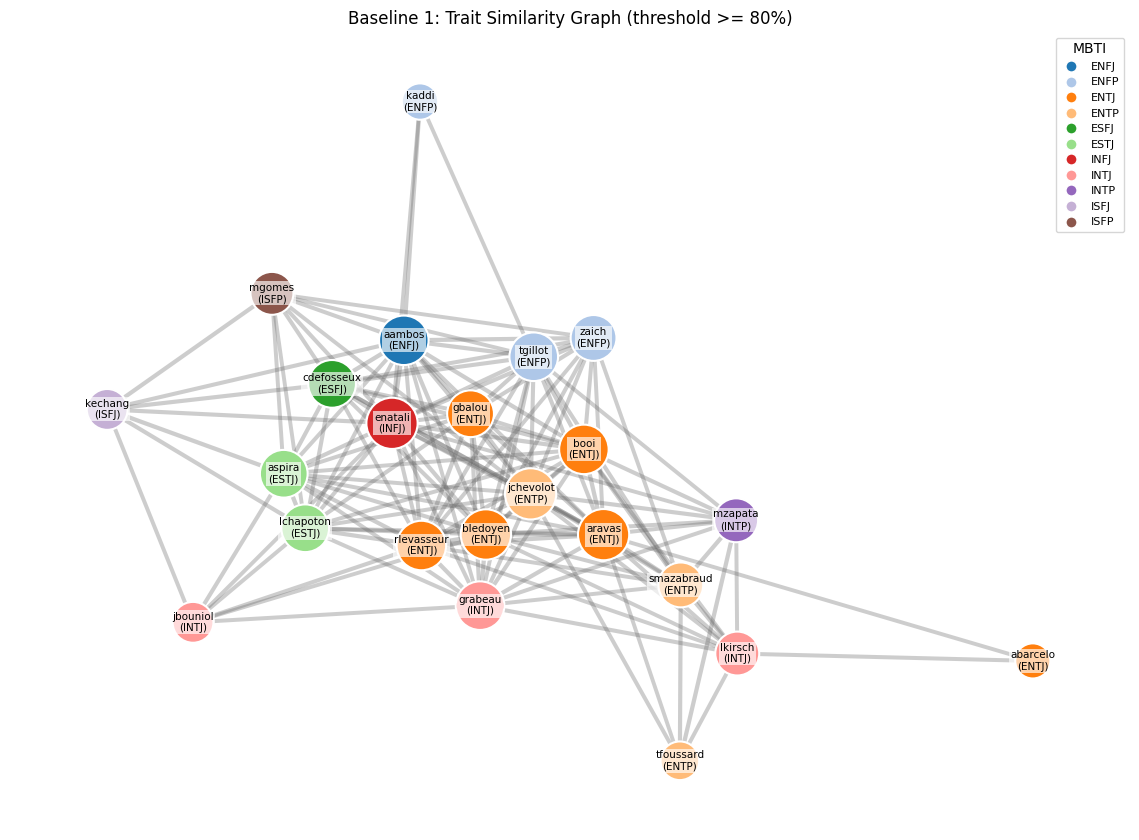

In [2]:
G_sim = G_base.copy()
students = df.index.tolist()
threshold = 0.80
sim_pairs = []

for i in range(len(students)):
    for j in range(i + 1, len(students)):
        u, v = students[i], students[j]
        diff = np.abs(df.loc[u, traits].values - df.loc[v, traits].values)
        sim = float(1.0 - diff.mean())
        if sim >= threshold:
            G_sim.add_edge(u, v, weight=sim)
            sim_pairs.append({
                "Student A": u, "MBTI A": df.loc[u, "mbti"],
                "Student B": v, "MBTI B": df.loc[v, "mbti"],
                "Similarity (%)": round(sim * 100, 1),
            })

sim_df = pd.DataFrame(sim_pairs).sort_values("Similarity (%)", ascending=False).reset_index(drop=True)
print(f"Similarity graph: {G_sim.number_of_nodes()} nodes, {G_sim.number_of_edges()} edges (density = {nx.density(G_sim):.2f})")
display(sim_df.head(10))

pos_sim = nx.spring_layout(G_sim, seed=42, k=0.7, weight="weight")
plot_network(G_sim, pos_sim, "Baseline 1: Trait Similarity Graph (threshold >= 80%)")

## 2. Baseline: Trait Contrast Graph

Here we test the opposite intuition: connecting students who sit on opposite sides of the 50% mark on the 5 dimensions. We keep the top 5 most contrasting links per student.

Contrast graph: 23 nodes, 87 edges


,Student A,MBTI A,Student B,MBTI B,Contrast (%)
0,abarcelo,ENTJ,kaddi,ENFP,24.8
1,kaddi,ENFP,lkirsch,INTJ,23.0
2,kaddi,ENFP,tfoussard,ENTP,21.0
3,abarcelo,ENTJ,mgomes,ISFP,19.8
4,abarcelo,ENTJ,jbouniol,INTJ,15.9
5,kaddi,ENFP,smazabraud,ENTP,15.6
6,abarcelo,ENTJ,kechang,ISFJ,15.4
7,kechang,ISFJ,tfoussard,ENTP,15.2
8,kaddi,ENFP,mzapata,INTP,14.4
9,jbouniol,INTJ,tfoussard,ENTP,14.1


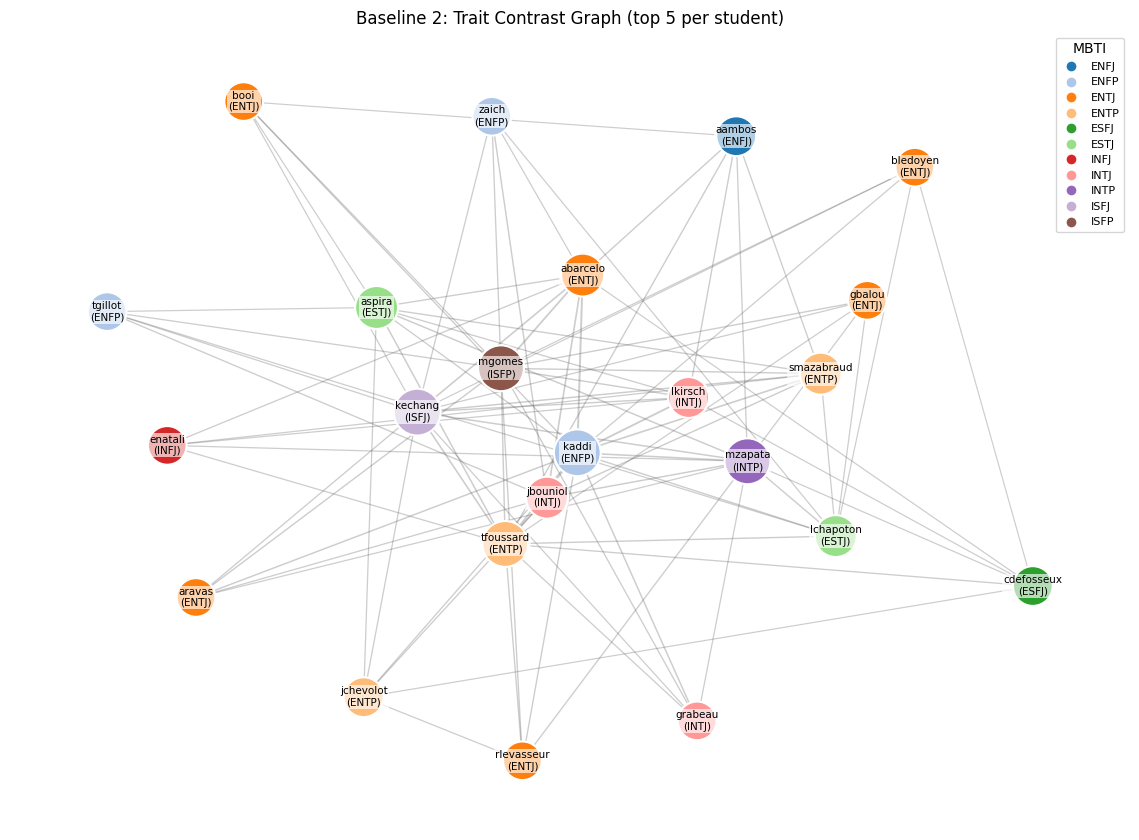

In [3]:
G_contrast = G_base.copy()
top_k = 5
centered = df[traits].values - 0.5
contrast_scores = {}

for i in range(len(students)):
    for j in range(i + 1, len(students)):
        opposition = 4.0 * np.maximum(0.0, -(centered[i] * centered[j]))
        contrast_scores[(i, j)] = float(opposition.mean())

for i, u in enumerate(students):
    neighbors = [
        (students[j], contrast_scores[(min(i, j), max(i, j))])
        for j in range(len(students)) if i != j
    ]
    neighbors.sort(key=lambda x: x[1], reverse=True)
    for v, score in neighbors[:top_k]:
        G_contrast.add_edge(u, v, weight=score)

contrast_df = pd.DataFrame([
    {
        "Student A": u, "MBTI A": df.loc[u, "mbti"],
        "Student B": v, "MBTI B": df.loc[v, "mbti"],
        "Contrast (%)": round(d["weight"] * 100, 1),
    }
    for u, v, d in G_contrast.edges(data=True)
]).sort_values("Contrast (%)", ascending=False).reset_index(drop=True)

print(f"Contrast graph: {G_contrast.number_of_nodes()} nodes, {G_contrast.number_of_edges()} edges")
display(contrast_df.head(10))

pos_con = nx.spring_layout(G_contrast, seed=42, k=0.7)
plot_network(G_contrast, pos_con, f"Baseline 2: Trait Contrast Graph (top {top_k} per student)")

## 3. Work-Group Compatibility Graph

Pure similarity creates a very dense graph where almost everyone is linked, while pure opposition pairs profiles that may clash on organization and communication. 

To model realistic project teams, we define an ideal partner vector for each student across the 5 traits:
- **Energy (`E`)**: complementary (`1 - E`), balancing outspoken and quieter team members.
- **Mind (`N`) & Nature (`T`)**: aligned (`N`, `T`), so teammates process ideas and feedback in a compatible way.
- **Tactics (`J`) & Identity (`A`)**: averaged with `0.65` (`(x + 0.65) / 2`), slightly favoring structure and emotional steadiness under deadlines.

We average the normalized Euclidean distance in both directions to get a symmetric score, then build an undirected $k$-NN graph ($k = 4$).

Compatibility graph (4-NN): 23 nodes, 67 edges, density = 0.26, connected = True, degree range = [4, 10]


,Student A,Type A,Student B,Type B,Compatibility (%)
0,grabeau,INTJ-A,rlevasseur,ENTJ-A,93.8
1,aravas,ENTJ-A,grabeau,INTJ-A,92.5
2,aambos,ENFJ-T,enatali,INFJ-T,92.2
3,bledoyen,ENTJ-A,grabeau,INTJ-A,91.6
4,aspira,ESTJ-T,lchapoton,ESTJ-T,90.3
5,gbalou,ENTJ-T,grabeau,INTJ-A,89.3
6,booi,ENTJ-A,enatali,INFJ-T,89.2
7,bledoyen,ENTJ-A,booi,ENTJ-A,89.1
8,bledoyen,ENTJ-A,gbalou,ENTJ-T,89.1
9,cdefosseux,ESFJ-T,kechang,ISFJ-T,89.1


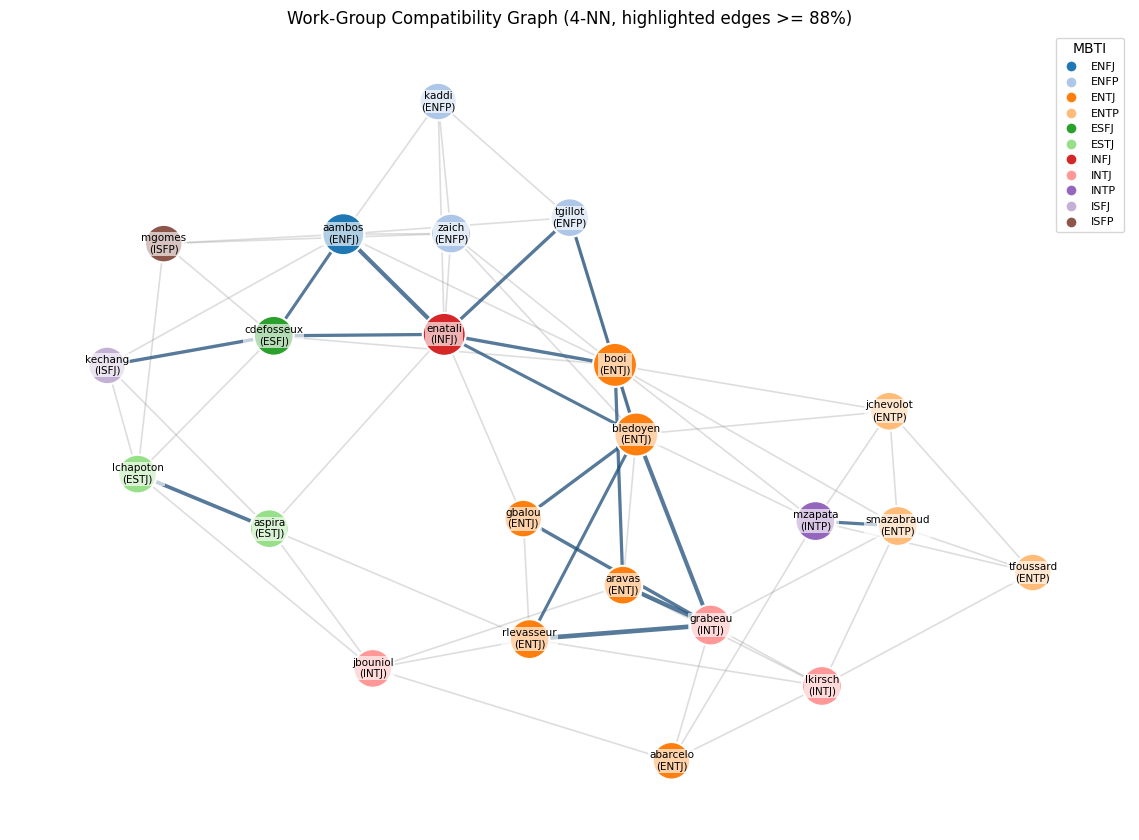

In [4]:
def ideal_partner(x, anchor=0.65):
    return np.array([
        1.0 - x[0],             # E: complementary energy
        x[1],                   # N: aligned intuition/sensing
        x[2],                   # T: aligned thinking/feeling
        0.5 * (x[3] + anchor),  # J: pulled toward structure
        0.5 * (x[4] + anchor),  # A: pulled toward calm stability
    ])


X = df[traits].values
X_ideal = np.array([ideal_partner(row) for row in X])
n = len(students)

compat_matrix = np.zeros((n, n))
compat_pairs = []

for i in range(n):
    for j in range(i + 1, n):
        u, v = students[i], students[j]
        d_ab = np.linalg.norm(X[j] - X_ideal[i]) / np.sqrt(len(traits))
        d_ba = np.linalg.norm(X[i] - X_ideal[j]) / np.sqrt(len(traits))
        score = float(1.0 - 0.5 * (d_ab + d_ba))

        compat_matrix[i, j] = compat_matrix[j, i] = score
        compat_pairs.append({
            "Student A": u, "Type A": f"{df.loc[u, 'mbti']}{df.loc[u, 'variant']}",
            "Student B": v, "Type B": f"{df.loc[v, 'mbti']}{df.loc[v, 'variant']}",
            "Compatibility (%)": round(score * 100, 1),
        })

G_compat = G_base.copy()
k_neighbors = 4
for i, u in enumerate(students):
    top_idx = [j for j in np.argsort(compat_matrix[i])[::-1] if j != i][:k_neighbors]
    for j in top_idx:
        G_compat.add_edge(u, students[j], weight=compat_matrix[i, j])

compat_df = pd.DataFrame(compat_pairs).sort_values("Compatibility (%)", ascending=False).reset_index(drop=True)
deg = dict(G_compat.degree())
print(
    f"Compatibility graph ({k_neighbors}-NN): {G_compat.number_of_nodes()} nodes, "
    f"{G_compat.number_of_edges()} edges, density = {nx.density(G_compat):.2f}, "
    f"connected = {nx.is_connected(G_compat)}, degree range = [{min(deg.values())}, {max(deg.values())}]"
)
display(compat_df.head(15))

pos_compat = nx.spring_layout(G_compat, seed=42, k=0.9, iterations=150, weight="weight")
plot_network(
    G_compat,
    pos_compat,
    f"Work-Group Compatibility Graph ({k_neighbors}-NN, highlighted edges >= 88%)",
    highlight_above=0.88,
)

## 4. Interactive HTML Graph

Export `G_compat` to an interactive HTML view (`graph.html`) using PyVis to explore local neighborhoods.

In [5]:
from pyvis.network import Network

net = Network(height="750px", width="100%", bgcolor="#ffffff", font_color="#222222", cdn_resources="in_line")
net.barnes_hut(gravity=-3500, central_gravity=0.3, spring_length=140)

for node, attrs in G_compat.nodes(data=True):
    tooltip = (
        f"{node} ({attrs['mbti']}{attrs['variant']})\n"
        f"E: {attrs['E']:.0%} | N: {attrs['N']:.0%} | T: {attrs['T']:.0%} | "
        f"J: {attrs['J']:.0%} | A: {attrs['A']:.0%}"
    )
    net.add_node(node, label=f"{node} ({attrs['mbti']})", title=tooltip, size=14 + 2 * G_compat.degree(node))

for u, v, attrs in G_compat.edges(data=True):
    w = attrs["weight"]
    net.add_edge(u, v, value=w, title=f"Compatibility: {w:.1%}")

net.write_html("graph.html", open_browser=False)
print("Saved interactive graph to graph.html")

Saved interactive graph to graph.html
